# M5.3 · 高频 / Tick 回测

> 高频策略在逐笔/逐 tick 尺度决策，订单的网络延迟、限价单排队位置、做市库存都直接决定盈亏。
> 本地无真实逐笔数据，本讲用**合成 tick** 演示机制（非真实行情）。

## 一、关键机制

1. **Tick 数据**：时间戳、中间价、bid/ask；
2. **延迟建模**：订单提交后经过 latency 个 tick 才到达撮合，高频下延迟即成本；
3. **队列位置**：限价单排队，需前方挂单被逐量消耗后才轮到自己成交；
4. **做市策略**：双边挂单赚价差，核心风险是单边行情中的库存累积；
5. **精度与性能**：逐 tick 事件循环，数据量大，需关注时间戳对齐与计算效率。

## 二、合成 Tick 与延迟/队列

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
from bt_lab2 import tick as tk
ticks = tk.simulate_ticks(2000)
lat = tk.LatencyModel(5)
q = tk.QueuePosition(); q.join(500); q.consume(500)
print('tick数=%d 延迟到达位置=%d 队列是否轮到=%s' % (len(ticks), lat.arrive_at(100), q.reached()))
print(ticks.head(3))

tick数=2000 延迟到达位置=105 队列是否轮到=True
   time         mid         bid         ask
0     0  100.018285  100.008285  100.028285
1     1   99.955894   99.945894   99.965894
2     2  100.000911   99.990911  100.010911


## 三、做市策略回测

In [2]:
mm = tk.market_making_backtest(ticks, half_spread=0.01, latency=5)
print('做市 final_pnl=%.2f 最大绝对库存=%d' % (mm['final_pnl'], mm['max_abs_inventory']))
path = mm['path']
print('库存均值=%.2f 末库存=%d' % (path['inventory'].mean(), path['inventory'].iloc[-1]))

做市 final_pnl=-414.30 最大绝对库存=100
库存均值=25.64 末库存=94


## 四、可视化

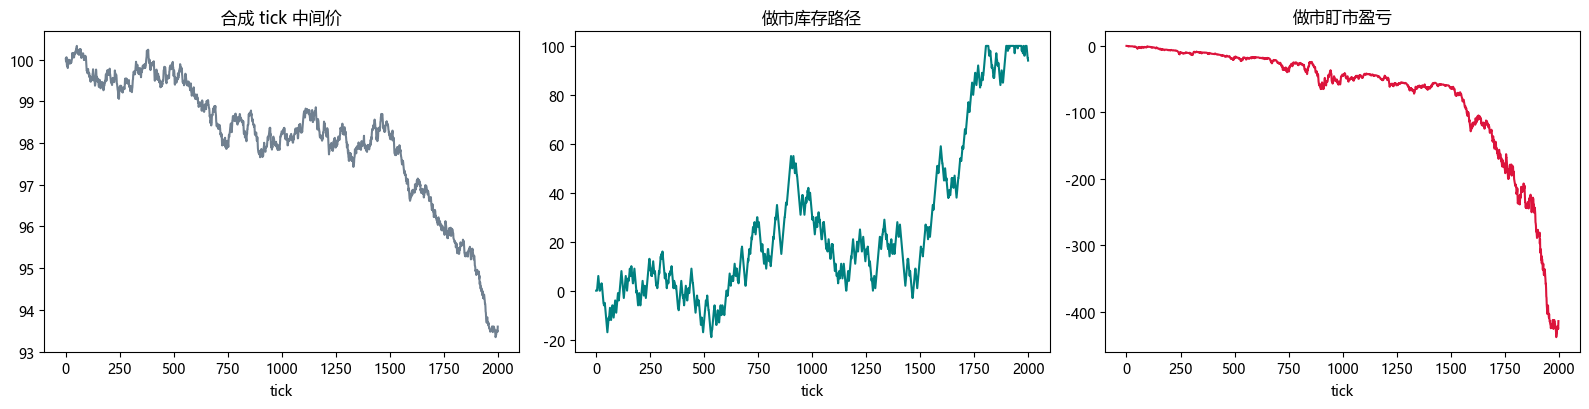

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].plot(ticks['time'], ticks['mid'], color='slategray')
ax[0].set_title('合成 tick 中间价'); ax[0].set_xlabel('tick')
ax[1].plot(path['time'], path['inventory'], color='teal')
ax[1].set_title('做市库存路径'); ax[1].set_xlabel('tick')
ax[2].plot(path['time'], path['pnl'], color='crimson')
ax[2].set_title('做市盯市盈亏'); ax[2].set_xlabel('tick')
plt.tight_layout(); plt.show()

## 五、面试要点

- **延迟如何影响高频策略？** 订单到达时行情可能已变化，延迟使套利窗口消失、限价单成交概率改变，低延迟是高频核心竞争力。
- **队列位置为何重要？** 限价单按时间优先排队，未轮到自己不会成交，需用队列模型估计成交概率，而非假设立即成交。
- **做市商如何管理库存风险？** 单边行情中库存累积产生方向性亏损，常用库存偏移报价、库存上限、动态价差控制。
- **合成 tick 回测的局限？** 无法还原真实成交的自相关、跳价与成交聚集，实盘前必须用真实逐笔数据验证。

## 六、练习

1. 改变 latency，观察做市盈亏如何变化。
2. 调整 half_spread，权衡价差收入与成交概率。
3. 加入库存偏移报价（库存高时压低买价），看库存是否更平稳。
4. 用更真实的跳跃-扩散过程生成 tick 并比较。